# step6_diagnostics

 **Owner:** P2 
 **Purpose:** Segment analysis by cold/warm, category, slate length and history length. 
 **Inputs:** Test-split scores from steps 2-5 (one file per model in `config.SCORES_DIR`: `impression_id`, `news_id`, `score`, covering every candidate of the Test split = MIND dev, 15 Nov). Labels and features are rebuilt here from the raw MIND-large dev and train files. 
 **Outputs:** `outputs/results_step6.csv` (one row per model) and, in `outputs/step6_diagnostics/`, one `.csv` per table and the figures. 

**How the pieces are defined**
- *Cold article*: fewer than `COLD_THRESHOLD` (10) impressions in the training data the model could see (training counts frozen at training time; see Section 0). Thresholds 5 and 20 are reported as sensitivity checks only.  
- *Cold / warm / mixed impression*: by the articles that were **clicked** in it (all cold / none cold / some of each), exactly as `utils/metrics.py`.
- *Test* = MIND dev (15 Nov). It is scored once here; no threshold or model is chosen from these results.

> Runtime: Colab. Run all cells top to bottom; keep outputs saved. Scoring runs once per model (about a minute each on the full Test split); the four analysis sections afterwards are quick.

In [1]:
# --- Setup: run this first, every session ---
# Where is the data?
#   None  -> the shared Google Drive folder (Colab, shortcut under My Drive; see README)
#   or the folder ON THIS COMPUTER that contains MINDlarge_train and MINDlarge_dev,
#   e.g. LOCAL_DATA = r"C:\Users\me\Downloads\MIND"
LOCAL_DATA = None
SCORES_PATH = None      # None = config.SCORES_DIR on the shared Drive; or a folder on this computer holding the score files
REPO_PATH = None        # local only: path of your clone of the group repo; None = clone it next to this notebook
REPO_URL = "https://github.com/Fdiannz/BT4222-Project-Group-4--MIND"   # copy the exact clone URL from the other notebooks if different

import os, sys, re, time, glob, subprocess
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and not LOCAL_DATA:
    drive.mount('/content/drive')

if REPO_PATH is None:
    REPO_PATH = "/content/BT4222-Project-Group-4--MIND" if IN_COLAB else os.path.abspath("BT4222-Project-Group-4--MIND")
    if os.path.isdir(REPO_PATH):
        subprocess.run(["git", "-C", REPO_PATH, "pull", "-q"])          # already cloned: just update
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, REPO_PATH], check=True)
sys.path.insert(0, REPO_PATH)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import config
from utils.data_utils import load_news, load_behaviors, explode_impressions
from utils.metrics import evaluate, evaluate_by_segment, topk, topk_diversity, add_rank, attach_scores, label_impression_segment

if LOCAL_DATA:
    TRAIN_DIR, DEV_DIR = (os.path.join(LOCAL_DATA, d) for d in ("MINDlarge_train", "MINDlarge_dev"))
    FIG = os.path.join(os.path.abspath("."), "step6_outputs")           # copy to the Drive's outputs/ afterwards
    RESULTS_CSV = f"{FIG}/results_step6.csv"
else:
    TRAIN_DIR, DEV_DIR = config.TRAIN_DIR, config.DEV_DIR
    FIG = "/content/drive/MyDrive/step6_outputs/step6_diagnostics"       # always your own Drive; copy to the shared outputs/ later
    RESULTS_CSV = "/content/drive/MyDrive/step6_outputs/results_step6.csv"
SCORES_DIR = SCORES_PATH or getattr(config, "SCORES_DIR", f"{config.DATA_DIR}/scores")
for d in (TRAIN_DIR, DEV_DIR):
    assert os.path.isfile(os.path.join(d, "behaviors.tsv")), (
        f"Cannot find {d}/behaviors.tsv - set LOCAL_DATA to the folder holding MINDlarge_train and MINDlarge_dev "
        "(or, on Drive, add the shared BT4222_Project folder as a shortcut directly under My Drive)")
os.makedirs(FIG, exist_ok=True)
print("Data   :", DEV_DIR, "\nScores :", SCORES_DIR, "\nOutputs:", FIG)

Mounted at /content/drive
Data   : /content/drive/MyDrive/BT4222_Project/data/raw/MINDlarge_dev 
Scores : /content/drive/MyDrive/BT4222_Project/data/scores 
Outputs: /content/drive/MyDrive/step6_outputs/step6_diagnostics


In [2]:
# --- Analysis settings (fixed in advance; do not tune these on the Test results) ---
COLD_T = config.COLD_THRESHOLD        # main cold threshold (10)
COLD_T_SENS = (5, 20)                 # sensitivity checks only
COUNT_WINDOW = "fit+tune"             # "fit+tune": counts from all training days (final models trained on both)
                                      # "fit": counts from the fit days only (9-13 Nov), use if the final models are NOT refitted on tune
TOP_K = config.TOP_K                  # length of the shown list (10)
SIM_THRESHOLD = getattr(config, "SIM_THRESHOLD", 0.85)   # near-duplicate cosine cutoff (only used if EMB is set)
EMB = None                            # not set: no agreed independent embedding yet; diversity is reported as category count only
                                      # Must NOT be the embedding the MMR re-ranker itself optimises (independent evaluation).
MODELS = [                            # Test-day score files only (checked with check_scores.py on 2 Nov); None = every file in SCORES_DIR
    "step2_popularity", "step2_category_ctr",
    "content_based", "ncf_nmf_neumf", "step3_feature_mlp", "step4_nrms_eval",
    "nrms_mmr_1.0", "nrms_mmr_0.9", "nrms_mmr_0.8", "nrms_mmr_0.7", "nrms_mmr_0.6", "nrms_mmr_0.5",
    "ncf_nmf_neumf_plus_id_masking_p0.1",   # P3's gap-diagnosis ablation: report as a labelled extra row, not a main model
]                                     # excluded on purpose: step4_nrms_tune (Tune day) and step4_nrms_train_sample (train sample)

SLATE_BINS, SLATE_LABELS = [0, 10, 20, 30, 50, 100, np.inf], ["<=10", "11-20", "21-30", "31-50", "51-100", ">100"]
HIST_BINS, HIST_LABELS = [-1, 0, 4, 19, 49, np.inf], ["0", "1-4", "5-19", "20-49", "50+"]
MIN_CLICK_SHARE = 0.002               # categories with fewer than 0.2% of Test clicks are left out of the category table
METRICS = ["auc", "mrr", "ndcg@5", "ndcg@10"]


def save(df, name):
    df.to_csv(f"{FIG}/{name}.csv")
    return df


def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})


# ---- figure helpers: readable names, one fixed colour per model, and a short list of models for the busy charts ----
SHORT = {"random (reference)": "Random", "step2_popularity": "Popularity", "step2_category_ctr": "Category CTR",
         "content_based": "Content-based", "ncf_nmf_neumf": "NeuMF",
         "ncf_nmf_neumf_plus_id_masking_p0.1": "NeuMF + ID masking (ablation)",
         "step3_feature_mlp": "Feature MLP", "step4_nrms_eval": "NRMS"}


def short(m):
    return SHORT.get(m) or ("NRMS + MMR " + m.rsplit("_", 1)[-1] if m.startswith("nrms_mmr_") else m)


FIG_MODELS = ["random (reference)", "step2_popularity", "step2_category_ctr", "content_based", "ncf_nmf_neumf",
              "step3_feature_mlp", "step4_nrms_eval", "nrms_mmr_0.8"]          # models drawn in the line and bar charts
COLORS = {"random (reference)": "#7f7f7f", "step2_popularity": "#E69F00", "step2_category_ctr": "#CC79A7",
          "content_based": "#009E73", "ncf_nmf_neumf": "#56B4E9", "step3_feature_mlp": "#D55E00",
          "step4_nrms_eval": "#0072B2", "nrms_mmr_0.8": "#0072B2"}


def fig_models(available):
    return [m for m in FIG_MODELS if m in available]


def style(m):      # random dotted, MMR dashed (same colour as NRMS), all others solid
    return ":" if m.startswith("random") else ("--" if m.startswith("nrms_mmr") else "-")


def line_fig(tbl, labels, xlabel, name):
    """AUC (left) and nDCG@10 minus the random reference (right) per bucket. Subtracting random removes the
    effect of bucket size on the metric, so the lines show what each model adds."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
    rnd = tbl.loc["random (reference)"]["ndcg@10"].reindex(labels)
    for m in fig_models(PER):
        auc = tbl.loc[m]["auc"].reindex(labels)
        lift = tbl.loc[m]["ndcg@10"].reindex(labels) - rnd
        for ax, y in zip(axes, (auc, lift)):
            ax.plot(labels, y, marker="o", ms=4, lw=1.2 if m.startswith("random") else 2, color=COLORS[m], ls=style(m), label=short(m))
    axes[0].set(title=f"AUC by {xlabel}", xlabel=xlabel, ylabel="AUC")
    axes[1].set(title=f"nDCG@10 minus random, by {xlabel}", xlabel=xlabel, ylabel="nDCG@10 minus random")
    axes[1].axhline(0, color="#7f7f7f", lw=.8)
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
    savefig(name)

## 0. Load the Test split, the cold flag and the score files
Candidates come from the raw MIND-large dev file (full slates, no negative sampling). The cold flag counts each article's **candidate impressions in the training data**, frozen at training time, because a model trained up to 14 Nov cannot learn about an article during the test day. This is the "train only" definition from `step0_eda` (Test: 17.9% of displays and 23.5% of clicks are cold at threshold 10). A running count through the test day would leave under 1% of impressions cold, too few to evaluate.

In [3]:
t0 = time.time()
beh_dev = load_behaviors(f"{DEV_DIR}/behaviors.tsv")
news_dev = load_news(f"{DEV_DIR}/news.tsv")
nids = pd.Index(news_dev["news_id"])
assert nids.is_unique, "news.tsv has duplicate news_id"

cand = explode_impressions(beh_dev, keep_cols=("impression_id",))        # one row per displayed candidate
cand["impression_id"] = cand["impression_id"].astype("int64")
code_ = nids.get_indexer(cand["news_id"])
assert (code_ >= 0).all(), f"{int((code_ < 0).sum())} candidates are missing from the dev news.tsv"
cand["news_id"] = code_.astype("int32")                                  # integer codes keep the merges small; nids decodes them
assert (cand["label"] >= 0).all(), "dev labels missing"
cat_codes, cat_names = pd.factorize(news_dev["category"])
cand["category"] = cat_codes[cand["news_id"].to_numpy()].astype("int8")

# one row per impression: slate length and history length (read from the raw strings)
imp = pd.DataFrame({"impression_id": beh_dev["impression_id"].astype("int64").to_numpy(),
                    "slate_len": (beh_dev["impressions"].str.count(" ") + 1).to_numpy(),
                    "hist_len": np.where(beh_dev["history"] == "", 0, beh_dev["history"].str.count(" ") + 1)})
assert imp["impression_id"].is_unique
imp = imp.set_index("impression_id")
imp["slate_bucket"] = pd.cut(imp["slate_len"], SLATE_BINS, labels=SLATE_LABELS)
imp["hist_bucket"] = pd.cut(imp["hist_len"], HIST_BINS, labels=HIST_LABELS)
del beh_dev
print(f"Test split: {imp.shape[0]:,} impressions, {len(cand):,} candidates, {int(cand['label'].sum()):,} clicks, "
      f"{len(nids):,} articles ({time.time() - t0:.0f}s)")

Test split: 376,471 impressions, 14,085,557 candidates, 574,845 clicks, 72,023 articles (72s)


In [4]:
# --- frozen training-time exposure counts per article ---
def exposure_counts(path, before=None, chunk=200_000):
    """Candidate impressions per article in a training behaviors file, optionally only before a timestamp."""
    b = load_behaviors(path)
    if before is not None:
        b = b[b["time"] < before]
    parts = []
    for s in range(0, len(b), chunk):
        c = explode_impressions(b.iloc[s:s + chunk], keep_cols=("impression_id",))
        parts.append(c.groupby("news_id").size())
        print(f"  chunk {s // chunk + 1}/{-(-len(b) // chunk)} done", end="\r")
    return pd.concat(parts).groupby(level=0).sum()


assert COUNT_WINDOW in ("fit+tune", "fit")
cache = f"{FIG}/cold_counts_{COUNT_WINDOW.replace('+', '_')}.csv"
counts = None
if os.path.exists(cache):
    counts = pd.read_csv(cache, index_col=0)["exposures"]
    print("Loaded cached counts:", cache)
elif COUNT_WINDOW == "fit+tune":                       # step0_eda already saved exactly this table
    for p in (f"{config.OUTPUT_DIR}/step0_eda/train_article_counts.parquet", "step0_eda_outputs/train_article_counts.parquet"):
        try:
            counts = pd.read_parquet(p)["exposures"]
            print("Reusing the step0_eda counts:", p)
            break
        except Exception:
            pass
if counts is None:
    t0 = time.time()
    before = pd.Timestamp(str(config.TUNE_DATE)).normalize() if COUNT_WINDOW == "fit" else None
    counts = exposure_counts(f"{TRAIN_DIR}/behaviors.tsv", before=before)
    print(f"\nCounted training impressions in {(time.time() - t0) / 60:.1f} min")
counts.rename("exposures").to_frame().to_csv(cache)

prior = counts.reindex(nids).fillna(0).astype("int64").to_numpy()        # per Test article, aligned with nids
cand["prior"] = prior[cand["news_id"].to_numpy()].astype("int32")
cand["is_cold"] = (cand["prior"] < COLD_T).astype("int8")
print(f"Window '{COUNT_WINDOW}': {int((prior < COLD_T).sum()):,} of {len(prior):,} Test-news articles are cold at T={COLD_T}")

Loaded cached counts: /content/drive/MyDrive/step6_outputs/step6_diagnostics/cold_counts_fit_tune.csv
Window 'fit+tune': 66,285 of 72,023 Test-news articles are cold at T=10


In [5]:
# impression segment (cold / warm / mixed) by the clicked articles, for the main threshold and the sensitivity thresholds
pos = cand.loc[cand["label"] == 1, ["impression_id", "prior"]].copy()
SEG = {}
for T in (COLD_T,) + tuple(COLD_T_SENS):
    pos["flag"] = (pos["prior"] < T).astype("int8")
    SEG[T] = label_impression_segment(pos.assign(label=1), "flag")

rows = []
for T in (COLD_T,) + tuple(COLD_T_SENS):
    cold = cand["prior"] < T
    share = SEG[T].value_counts(normalize=True) * 100
    rows.append({"threshold": T, "cold_displays_%": 100 * cold.mean(),
                 "cold_clicks_%": 100 * (cold & (cand["label"] == 1)).sum() / (cand["label"] == 1).sum(),
                 "impressions_cold_%": share.get("cold", 0), "impressions_mixed_%": share.get("mixed", 0),
                 "impressions_warm_%": share.get("warm", 0)})
seg_sizes = save(pd.DataFrame(rows).set_index("threshold").round(2), "cold_segment_sizes")
display(seg_sizes)
print("With COUNT_WINDOW='fit+tune' the T=10 row should equal step0_eda's train-only table "
      "(17.93 / 23.46 / 20.51 / 9.69 / 69.81).")

# cold share among each impression's candidates (the baseline for the top-k exposure ratio)
cold_cand_share = cand.groupby("impression_id")["is_cold"].mean()
CAND_COLD_SHARE = float(cold_cand_share[imp["slate_len"].reindex(cold_cand_share.index) >= TOP_K].mean())
print(f"Cold share of candidates in impressions with at least {TOP_K} candidates: {100 * CAND_COLD_SHARE:.1f}%")

,cold_displays_%,cold_clicks_%,impressions_cold_%,impressions_mixed_%,impressions_warm_%
threshold,,,,,
10,17.93,23.46,20.51,9.69,69.81
5,11.84,17.04,15.23,7.54,77.24
20,28.29,32.87,28.33,11.46,60.20


With COUNT_WINDOW='fit+tune' the T=10 row should equal step0_eda's train-only table (17.93 / 23.46 / 20.51 / 9.69 / 69.81).
Cold share of candidates in impressions with at least 10 candidates: 20.6%


In [6]:
# --- score files ---
def load_scores(path):
    """Read one score file and translate it to the integer codes used here."""
    s = pd.read_parquet(path) if path.endswith(".parquet") else pd.read_csv(path, dtype={"news_id": str})
    missing = {"impression_id", "news_id", "score"} - set(s.columns)
    if missing:
        raise ValueError(f"score file lacks columns {sorted(missing)}; expected impression_id, news_id, score")
    s = s[["impression_id", "news_id", "score"]].copy()
    s["impression_id"] = s["impression_id"].astype("int64")
    c = nids.get_indexer(s["news_id"].astype(str))
    if (c < 0).any():
        raise ValueError(f"{int((c < 0).sum())} news_ids are not in the Test news table - is this a Test-split score file?")
    s["news_id"] = c.astype("int32")
    return s


files = {}
for p in sorted(glob.glob(f"{SCORES_DIR}/*.parquet") + glob.glob(f"{SCORES_DIR}/*.csv")):
    stem = os.path.splitext(os.path.basename(p))[0]
    if stem.startswith(("_", ".")) or (MODELS is not None and stem not in MODELS):
        continue
    files[stem] = p
if MODELS is not None:                                          # a typo or a missing upload must stop the run, not shrink the table
    absent = [m for m in MODELS if m not in files]
    assert not absent, f"MODELS lists files that are not in {SCORES_DIR}: {absent}"
print(f"{len(files)} score file(s) in {SCORES_DIR}:", ", ".join(files) or "none yet")
if not files:
    print("No score files found. Only the random reference will run; rerun this notebook once the models have written their Test scores.")

EMB_CODES = None
if EMB is not None:
    EMB_CODES = {int(nids.get_loc(k)): np.asarray(v) for k, v in EMB.items() if k in nids}

13 score file(s) in /content/drive/MyDrive/BT4222_Project/data/scores: content_based, ncf_nmf_neumf, ncf_nmf_neumf_plus_id_masking_p0.1, nrms_mmr_0.5, nrms_mmr_0.6, nrms_mmr_0.7, nrms_mmr_0.8, nrms_mmr_0.9, nrms_mmr_1.0, step2_category_ctr, step2_popularity, step3_feature_mlp, step4_nrms_eval


In [7]:
def near_duplicate_rate(top, emb_codes, thr, k):
    """Share of top-k lists that contain at least one pair of articles with cosine similarity >= thr."""
    size = top.groupby("impression_id", sort=False)["news_id"].transform("size")
    full = top[size == k].sort_values("impression_id", kind="stable")
    ids = pd.Index(list(emb_codes.keys()))
    E = np.stack(list(emb_codes.values())).astype(np.float32)
    E /= np.maximum(np.linalg.norm(E, axis=1, keepdims=True), 1e-12)
    idx = ids.get_indexer(full["news_id"]).reshape(-1, k)
    hit = np.zeros(len(idx), dtype=bool)
    off = ~np.eye(k, dtype=bool)
    for s in range(0, len(idx), 20000):
        v = E[idx[s:s + 20000]]
        sim = np.einsum("nkd,njd->nkj", v, v)
        hit[s:s + 20000] = ((sim >= thr) & off).any((1, 2))
    return float(hit.mean())


PER, CLK, TOPSUM, STATUS = {}, {}, {}, []


def score_one(name, df):
    """Everything model-specific, computed once on the 14M-row table; the sections below only group these small tables."""
    per = evaluate(df, "score", per_impression=True).join(imp, on="impression_id")      # valid impressions only
    dfr = add_rank(df, "score")
    clk = dfr.loc[dfr["label"] == 1, ["impression_id", "news_id", "category", "prior", "rank"]]
    clk = clk.join(imp[["slate_len"]], on="impression_id")
    top = dfr[dfr["rank"] <= TOP_K]
    div = topk_diversity(top, "category", EMB_CODES, cold_col="is_cold", k=TOP_K)
    out = {"top_unique_categories": div["unique_categories"], "top_cold_share": div["cold_share"],
           "top_cold_exposure_ratio": div["cold_share"] / CAND_COLD_SHARE,
           "top_lists": div["n_lists"], "top_short_lists_excluded": div["n_short_lists_excluded"]}
    if EMB_CODES is not None:
        out["top_intra_list_sim"] = div["intra_list_sim"]
        out["top_near_duplicate_rate"] = near_duplicate_rate(top, EMB_CODES, SIM_THRESHOLD, TOP_K)
    return per, clk, out


rng = np.random.default_rng(config.SEED)
todo = {"random (reference)": None, **files}
for name, path in todo.items():
    t0 = time.time()
    try:
        df = cand.assign(score=rng.random(len(cand))) if path is None else attach_scores(cand, load_scores(path))
        PER[name], CLK[name], TOPSUM[name] = score_one(name, df)
        STATUS.append({"model": name, "status": "ok", "seconds": round(time.time() - t0)})
        print(f"{name}: scored in {time.time() - t0:.0f}s  (nDCG@10 {PER[name]['ndcg@10'].mean():.4f}, AUC {PER[name]['auc'].mean():.4f})")
    except Exception as e:                                         # a bad file must be visible, never silently dropped
        STATUS.append({"model": name, "status": f"SKIPPED: {e}", "seconds": round(time.time() - t0)})
        print(f"!! {name} SKIPPED: {e}")
    df = None
display(save(pd.DataFrame(STATUS).set_index("model"), "model_status"))

random (reference): scored in 32s  (nDCG@10 0.2872, AUC 0.5002)
content_based: scored in 83s  (nDCG@10 0.3349, AUC 0.5647)
ncf_nmf_neumf: scored in 70s  (nDCG@10 0.2903, AUC 0.5185)
ncf_nmf_neumf_plus_id_masking_p0.1: scored in 75s  (nDCG@10 0.2866, AUC 0.5109)
nrms_mmr_0.5: scored in 74s  (nDCG@10 0.3510, AUC 0.6080)
nrms_mmr_0.6: scored in 77s  (nDCG@10 0.3616, AUC 0.6159)
nrms_mmr_0.7: scored in 84s  (nDCG@10 0.3706, AUC 0.6218)
nrms_mmr_0.8: scored in 80s  (nDCG@10 0.3770, AUC 0.6255)
nrms_mmr_0.9: scored in 79s  (nDCG@10 0.3809, AUC 0.6277)
nrms_mmr_1.0: scored in 75s  (nDCG@10 0.3829, AUC 0.6288)
step2_category_ctr: scored in 73s  (nDCG@10 0.2972, AUC 0.5315)
step2_popularity: scored in 77s  (nDCG@10 0.3729, AUC 0.6293)
step3_feature_mlp: scored in 87s  (nDCG@10 0.3377, AUC 0.5751)
step4_nrms_eval: scored in 82s  (nDCG@10 0.3829, AUC 0.6288)


,status,seconds
model,,
random (reference),ok,32
content_based,ok,83
ncf_nmf_neumf,ok,70
ncf_nmf_neumf_plus_id_masking_p0.1,ok,75
nrms_mmr_0.5,ok,74
nrms_mmr_0.6,ok,77
nrms_mmr_0.7,ok,84
nrms_mmr_0.8,ok,80
nrms_mmr_0.9,ok,79


## 1. By cold/warm article
**What this does:** splits the Test impressions by whether the clicked articles were cold (fewer than 10 training impressions), warm, or a mix, and reports the same metrics as the overall evaluation for each group. A second view works per click instead of per impression: for every click, where did the model rank the clicked article, split by whether that article is cold or warm. The click-level view is more stable because mixed impressions do not blur it.
**Why:** the project asks whether rarely shown articles get a fair chance at the top of the list. A model that only wins on warm articles hides exactly the gap we care about. Threshold 10 is fixed in advance; 5 and 20 are sensitivity checks, not alternatives to choose from.

In [8]:
def seg_table(T):
    rows = []
    for m, per in PER.items():
        s = per["impression_id"].map(SEG[T])
        for seg in ["all", "cold", "mixed", "warm"]:
            sub = per if seg == "all" else per[s == seg]
            rows.append({"model": m, "segment": seg, "n_impressions": len(sub), **sub[METRICS].mean().round(4).to_dict()})
    return pd.DataFrame(rows)


def click_table(T):
    rows = []
    for m, c in CLK.items():
        flag = np.where(c["prior"] < T, "cold", "warm")
        rr, rank_pct = 1 / c["rank"], c["rank"] / c["slate_len"]
        for seg in ["all", "cold", "warm"]:
            k = np.ones(len(c), bool) if seg == "all" else flag == seg
            rows.append({"model": m, "clicked_article": seg, "n_clicks": int(k.sum()), "click_rr": rr[k].mean(),
                         "hit@5": (c["rank"][k] <= 5).mean(), "hit@10": (c["rank"][k] <= 10).mean(),
                         "median_rank_pct": rank_pct[k].median()})
    return pd.DataFrame(rows).round(4)


SEGT = {T: save(seg_table(T), f"cold_warm_impressions_T{T}") for T in SEG}
CLKT = {T: save(click_table(T), f"cold_warm_clicks_T{T}") for T in SEG}

print(f"Impression segments, threshold {COLD_T} (cold = every clicked article cold):")
display(SEGT[COLD_T].pivot(index="model", columns="segment", values="ndcg@10")[["all", "cold", "mixed", "warm"]]
        .rename_axis(columns="nDCG@10").round(4))
display(SEGT[COLD_T].set_index(["model", "segment"]))
print(f"Per click, threshold {COLD_T} (hit@10 = clicked article is in the top 10; median_rank_pct = rank / slate length):")
display(CLKT[COLD_T].set_index(["model", "clicked_article"]))
print("Sensitivity - nDCG@10 on cold impressions by threshold:")
display(pd.DataFrame({f"T={T}": SEGT[T][SEGT[T]["segment"] == "cold"].set_index("model")["ndcg@10"] for T in SEG}))

Impression segments, threshold 10 (cold = every clicked article cold):


nDCG@10,all,cold,mixed,warm
model,,,,
content_based,0.3349,0.4665,0.2462,0.3085
ncf_nmf_neumf,0.2903,0.3646,0.1737,0.2847
ncf_nmf_neumf_plus_id_masking_p0.1,0.2866,0.3529,0.1623,0.2844
nrms_mmr_0.5,0.3510,0.4223,0.2447,0.3448
nrms_mmr_0.6,0.3616,0.4280,0.2608,0.3561
nrms_mmr_0.7,0.3706,0.4333,0.2748,0.3655
nrms_mmr_0.8,0.3770,0.4378,0.2846,0.3719
nrms_mmr_0.9,0.3809,0.4409,0.2908,0.3758
nrms_mmr_1.0,0.3829,0.4426,0.2938,0.3777


n_impressions     auc     mrr  \
model                              segment                                  
random (reference)                 all             376471  0.5002  0.2193   
                                   cold             77199  0.4994  0.2985   
                                   mixed            36465  0.5007  0.1140   
                                   warm            262807  0.5004  0.2106   
content_based                      all             376471  0.5647  0.2559   
                                   cold             77199  0.6243  0.3794   
                                   mixed            36465  0.5867  0.1485   
                                   warm            262807  0.5442  0.2345   
ncf_nmf_neumf                      all             376471  0.5185  0.2212   
                                   cold             77199  0.5040  0.2802   
                                   mixed            36465  0.5212  0.1089   
                                   warm            262807  0.5224  0.2195   
ncf_nmf_neumf_plus_id_masking_p0.1 all             376471  0.5109  0.2190   
                                   cold             77199  0.4816  0.2718   
                                   mixed            36465  0.4978  0.1038   
                                   warm            262807  0.5213  0.2195   
nrms_mmr_0.5                       all             376471  0.6080  0.2752   
                                   cold             77199  0.5591  0.3383   
                                   mixed            36465  0.6277  0.1558   
                                   warm            262807  0.6196  0.2732   
nrms_mmr_0.6                       all             376471  0.6159  0.2799   
                                   cold             77199  0.5648  0.3410   
                                   mixed            36465  0.6368  0.1613   
                                   warm            262807  0.6280  0.2784   
nrms_mmr_0.7                       all             376471  0.6218  0.2841   
                                   cold             77199  0.5697  0.3440   
                                   mixed            36465  0.6432  0.1661   
                                   warm            262807  0.6341  0.2829   
nrms_mmr_0.8                       all             376471  0.6255  0.2874   
                                   cold             77199  0.5731  0.3468   
                                   mixed            36465  0.6470  0.1695   
                                   warm            262807  0.6378  0.2863   
nrms_mmr_0.9                       all             376471  0.6277  0.2896   
                                   cold             77199  0.5755  0.3488   
                                   mixed            36465  0.6491  0.1716   
                                   warm            262807  0.6400  0.2886   
nrms_mmr_1.0                       all             376471  0.6288  0.2907   
                                   cold             77199  0.5767  0.3500   
                                   mixed            36465  0.6503  0.1729   
                                   warm            262807  0.6411  0.2897   
step2_category_ctr                 all             376471  0.5315  0.2183   
                                   cold             77199  0.4789  0.2482   
                                   mixed            36465  0.5576  0.1142   
                                   warm            262807  0.5433  0.2240   
step2_popularity                   all             376471  0.6293  0.2869   
                                   cold             77199  0.5550  0.2985   
                                   mixed            36465  0.6022  0.1472   
                                   warm            262807  0.6549  0.3029   
step3_feature_mlp                  all             376471  0.5751  0.2562   
                                   cold             77199  0.6857  0.4269   
                                   mixed

Per click, threshold 10 (hit@10 = clicked article is in the top 10; median_rank_pct = rank / slate length):


n_clicks  click_rr  \
model                              clicked_article                       
random (reference)                 all                574845    0.1787   
                                   cold               134863    0.2197   
                                   warm               439982    0.1662   
content_based                      all                574845    0.2127   
                                   cold               134863    0.2893   
                                   warm               439982    0.1892   
ncf_nmf_neumf                      all                574845    0.1807   
                                   cold               134863    0.1999   
                                   warm               439982    0.1748   
ncf_nmf_neumf_plus_id_masking_p0.1 all                574845    0.1783   
                                   cold               134863    0.1901   
                                   warm               439982    0.1747   
nrms_mmr_0.5                       all                574845    0.2299   
                                   cold               134863    0.2571   
                                   warm               439982    0.2216   
nrms_mmr_0.6                       all                574845    0.2348   
                                   cold               134863    0.2606   
                                   warm               439982    0.2269   
nrms_mmr_0.7                       all                574845    0.2392   
                                   cold               134863    0.2641   
                                   warm               439982    0.2316   
nrms_mmr_0.8                       all                574845    0.2426   
                                   cold               134863    0.2673   
                                   warm               439982    0.2350   
nrms_mmr_0.9                       all                574845    0.2447   
                                   cold               134863    0.2693   
                                   warm               439982    0.2372   
nrms_mmr_1.0                       all                574845    0.2459   
                                   cold               134863    0.2707   
                                   warm               439982    0.2384   
step2_category_ctr                 all                574845    0.1809   
                                   cold               134863    0.1842   
                                   warm               439982    0.1799   
step2_popularity                   all                574845    0.2391   
                                   cold               134863    0.2113   
                                   warm               439982    0.2476   
step3_feature_mlp                  all                574845    0.2150   
                                   cold               134863    0.3573   
                                   warm               439982    0.1714   
step4_nrms_eval                    all                574845    0.2459   
                                   cold               134863    0.2707   
                                   warm               439982    0.2384   

                                                     hit@5  hit@10  \
model                              clicked_article                   
random (reference)                 all              0.2682  0.4309   
                                   cold             0.3411  0.5139   
                                   warm             0.2459  0.4054   
content_based                      all              0.3209  0.4953   
                                   cold             0.4451  0.6107   
                                   warm             0.2828  0.4599   
ncf_nmf_neumf                      all              0.2709  0.4385   
                                   cold             0.3175  0.4995   
                                   warm             0.2566  0.4198   
ncf_nmf_neumf_plus_id_mas

Sensitivity - nDCG@10 on cold impressions by threshold:


,T=10,T=5,T=20
model,,,
random (reference),0.3815,0.4222,0.3467
content_based,0.4665,0.4850,0.4163
ncf_nmf_neumf,0.3646,0.4084,0.3276
ncf_nmf_neumf_plus_id_masking_p0.1,0.3529,0.3973,0.3137
nrms_mmr_0.5,0.4223,0.4766,0.3978
nrms_mmr_0.6,0.4280,0.4826,0.4044
nrms_mmr_0.7,0.4333,0.4884,0.4098
nrms_mmr_0.8,0.4378,0.4930,0.4141
nrms_mmr_0.9,0.4409,0.4961,0.4171


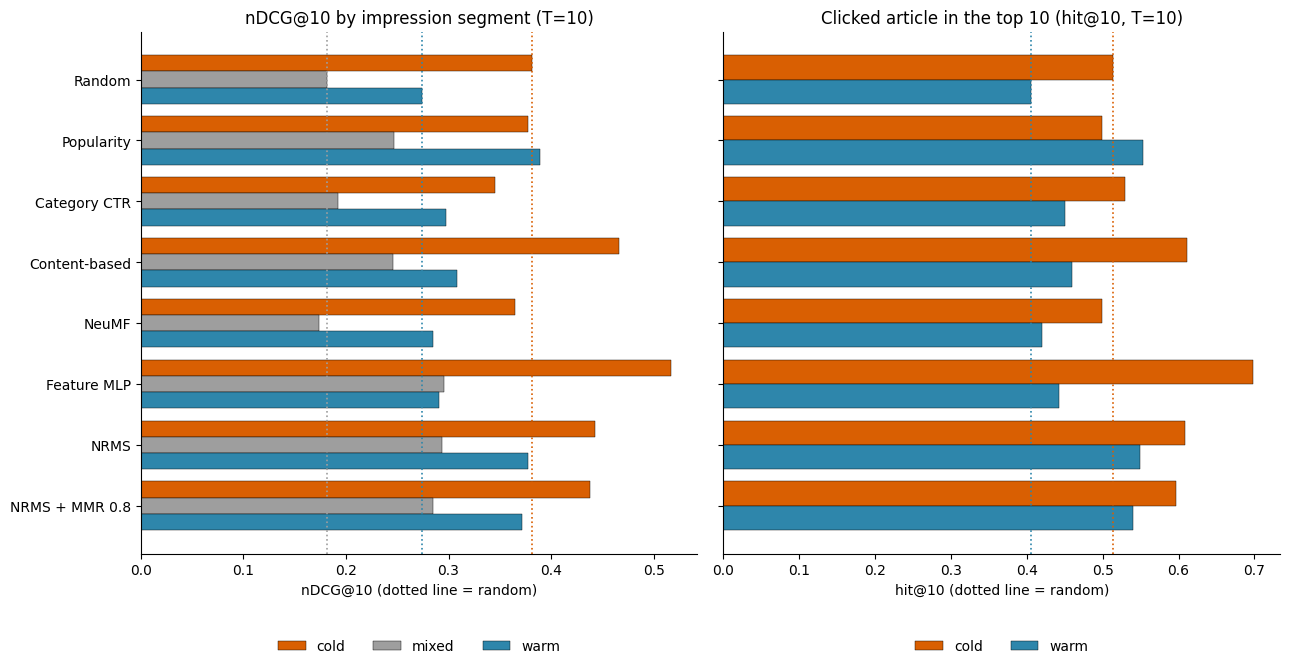

In [9]:
ms = fig_models(PER)
seg = SEGT[COLD_T].pivot(index="model", columns="segment", values="ndcg@10").loc[ms]
clk = CLKT[COLD_T][CLKT[COLD_T]["clicked_article"] != "all"].pivot(index="model", columns="clicked_article", values="hit@10").loc[ms]


def hbars(ax, df, cols, colors, title, xlabel):
    h = 0.8 / len(cols)
    for j, (c, col) in enumerate(zip(cols, colors)):
        ax.barh(np.arange(len(df)) + (j - (len(cols) - 1) / 2) * h, df[c], height=h, color=col, edgecolor="black", linewidth=.3, label=c)
        if "random (reference)" in df.index:
            ax.axvline(df.loc["random (reference)", c], color=col, ls=":", lw=1.2)        # dotted line = the random reference
    ax.set_yticks(range(len(df)), [short(m) for m in df.index])
    ax.set(title=title, xlabel=xlabel)
    ax.legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=len(cols), frameon=False)


fig, axes = plt.subplots(1, 2, figsize=(13, 0.55 * len(ms) + 2.4), sharey=True)
hbars(axes[0], seg, ["cold", "mixed", "warm"], ["#d95f02", "#9e9e9e", "#2e86ab"], f"nDCG@10 by impression segment (T={COLD_T})", "nDCG@10 (dotted line = random)")
hbars(axes[1], clk, ["cold", "warm"], ["#d95f02", "#2e86ab"], f"Clicked article in the top 10 (hit@10, T={COLD_T})", "hit@10 (dotted line = random)")
axes[0].invert_yaxis()          # axes share y: invert once so the first model is on top and cold is the top bar of each group
savefig("fig_cold_warm")

## 2. By category
**What this does:** for each article category, how often the clicked article of that category is placed in the top 10, and its mean reciprocal rank (click-level, because a category belongs to a candidate, not to a whole impression). Categories with under 0.2% of Test clicks are left out because their rates would be noise.
**Why:** a model can look strong overall by ranking the two large categories (news, sports) well while failing small ones. This is also the reference point for the diversity step: it shows whether MMR re-ranking helps or hurts the categories a plain relevance model neglects.

,n_clicks,content_based,ncf_nmf_neumf,ncf_nmf_neumf_plus_id_masking_p0.1,nrms_mmr_0.5,nrms_mmr_0.6,nrms_mmr_0.7,nrms_mmr_0.8,nrms_mmr_0.9,nrms_mmr_1.0,random (reference),step2_category_ctr,step2_popularity,step3_feature_mlp,step4_nrms_eval
category,,,,,,,,,,,,,,,
sports,133456,0.4430,0.4815,0.4474,0.5200,0.5538,0.5890,0.6183,0.6391,0.6530,0.4978,0.7786,0.7316,0.8723,0.6530
news,133378,0.5534,0.4452,0.4175,0.5063,0.5152,0.5246,0.5306,0.5326,0.5336,0.4589,0.4341,0.5521,0.5440,0.5336
lifestyle,97119,0.5986,0.5470,0.5294,0.5897,0.6093,0.6256,0.6332,0.6360,0.6361,0.4980,0.3812,0.6006,0.4860,0.6361
foodanddrink,34821,0.5404,0.3933,0.3832,0.4868,0.5052,0.5146,0.5181,0.5200,0.5202,0.3885,0.1010,0.5118,0.1587,0.5202
tv,28678,0.4201,0.3773,0.3452,0.5188,0.5445,0.5578,0.5628,0.5593,0.5548,0.3768,0.9965,0.6299,0.6034,0.5548
health,23127,0.3569,0.3407,0.4461,0.3591,0.4175,0.4447,0.4522,0.4526,0.4514,0.2296,0.0649,0.2470,0.1746,0.4514
finance,21099,0.4205,0.3520,0.3430,0.3787,0.3899,0.3963,0.3937,0.3943,0.3914,0.3461,0.1474,0.1989,0.1944,0.3914
music,19440,0.5537,0.4526,0.5020,0.5923,0.6096,0.6186,0.6190,0.6137,0.6078,0.4843,0.9759,0.3769,0.4184,0.6078
movies,17806,0.5868,0.2593,0.4179,0.3476,0.3562,0.3740,0.3967,0.4185,0.4341,0.3666,0.1022,0.1600,0.1310,0.4341


,n_clicks,content_based,ncf_nmf_neumf,ncf_nmf_neumf_plus_id_masking_p0.1,nrms_mmr_0.5,nrms_mmr_0.6,nrms_mmr_0.7,nrms_mmr_0.8,nrms_mmr_0.9,nrms_mmr_1.0,random (reference),step2_category_ctr,step2_popularity,step3_feature_mlp,step4_nrms_eval
category,,,,,,,,,,,,,,,
sports,133456,0.1551,0.1511,0.1420,0.2344,0.2406,0.2485,0.2563,0.2626,0.2675,0.1836,0.2287,0.3805,0.4305,0.2675
news,133378,0.2627,0.1732,0.1644,0.2263,0.2281,0.2301,0.2317,0.2325,0.2328,0.2023,0.1575,0.2289,0.2388,0.2328
lifestyle,97119,0.3042,0.3092,0.3090,0.3201,0.3257,0.3299,0.3325,0.3339,0.3344,0.2407,0.1365,0.2503,0.1777,0.3344
foodanddrink,34821,0.2252,0.1193,0.1162,0.1915,0.1959,0.1973,0.1970,0.1961,0.1952,0.1403,0.0432,0.2943,0.0607,0.1952
tv,28678,0.1235,0.1212,0.1121,0.1806,0.1872,0.1922,0.1949,0.1958,0.1952,0.1397,0.6782,0.1630,0.1532,0.1952
health,23127,0.1572,0.1966,0.2112,0.1734,0.1840,0.1919,0.1962,0.1976,0.1970,0.0981,0.0376,0.0854,0.0653,0.1970
finance,21099,0.1623,0.1686,0.1649,0.1520,0.1555,0.1570,0.1570,0.1565,0.1560,0.1374,0.0513,0.0651,0.0669,0.1560
music,19440,0.2144,0.1711,0.1843,0.2677,0.2733,0.2795,0.2815,0.2820,0.2812,0.2053,0.5109,0.1057,0.1232,0.2812
movies,17806,0.2777,0.0899,0.1399,0.1404,0.1399,0.1415,0.1447,0.1483,0.1520,0.1353,0.0449,0.0575,0.0509,0.1520


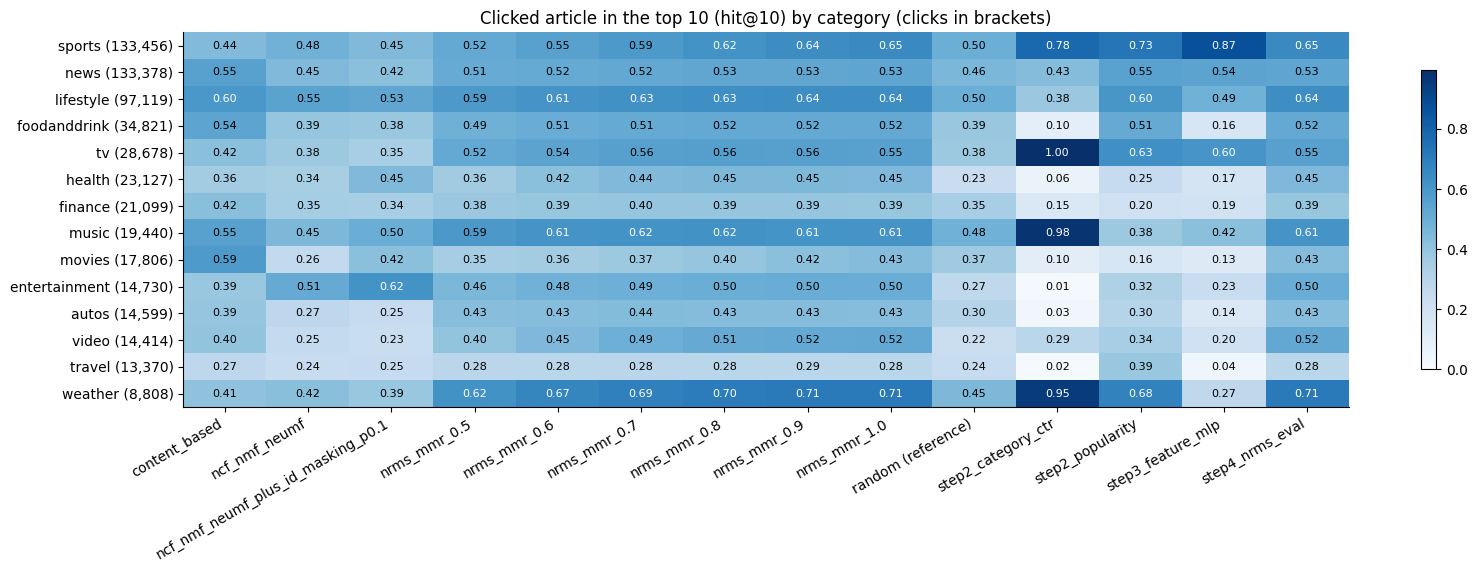

In [10]:
frames = []
for m, c in CLK.items():
    g = c.assign(rr=1 / c["rank"], hit10=(c["rank"] <= 10)).groupby("category").agg(
        n_clicks=("rr", "size"), click_rr=("rr", "mean"), hit10=("hit10", "mean"))
    g["model"], g["category"] = m, cat_names[g.index]
    frames.append(g.reset_index(drop=True))
cat_long = pd.concat(frames)
keep = cat_long.groupby("category")["n_clicks"].first()
keep = keep[keep >= MIN_CLICK_SHARE * len(next(iter(CLK.values())))].index
cat_long = cat_long[cat_long["category"].isin(keep)]
cat_hit = cat_long.pivot(index="category", columns="model", values="hit10")
cat_rr = cat_long.pivot(index="category", columns="model", values="click_rr")
cat_n = cat_long.groupby("category")["n_clicks"].first().rename("n_clicks")
order = cat_n.sort_values(ascending=False).index
cat_hit, cat_rr = cat_hit.loc[order], cat_rr.loc[order]
display(save(cat_n.loc[order].to_frame().join(cat_hit.round(4)), "category_hit10"))
display(save(cat_n.loc[order].to_frame().join(cat_rr.round(4)), "category_click_rr"))

fig, ax = plt.subplots(figsize=(1.2 + 1.1 * cat_hit.shape[1], 0.5 + 0.38 * len(cat_hit)))
im = ax.imshow(cat_hit.to_numpy(), aspect="auto", cmap="Blues", vmin=0)
ax.set_xticks(range(cat_hit.shape[1]), cat_hit.columns, rotation=30, ha="right")
ax.set_yticks(range(len(cat_hit)), [f"{c} ({n:,})" for c, n in zip(cat_hit.index, cat_n.loc[order])])
for i in range(cat_hit.shape[0]):
    for j in range(cat_hit.shape[1]):
        v = cat_hit.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > cat_hit.to_numpy().max() * .6 else "black")
ax.set_title("Clicked article in the top 10 (hit@10) by category (clicks in brackets)")
fig.colorbar(im, ax=ax, shrink=.8)
savefig("fig_category_hit10")

## 3. By slate length bucket
**What this does:** per-impression metrics averaged within buckets of how many candidates the impression showed.
**Why:** slate length changes the task. With 10 or fewer candidates there is nothing to re-rank for a top-10 list; long slates are where a model must surface the right article among many. Metrics are also not comparable across lengths (a random ranking scores better on short slates), so read each bucket against the random reference.

Share of scored impressions per bucket (%): {'<=10': 25.1, '11-20': 21.2, '21-30': 13.2, '31-50': 15.4, '51-100': 17.0, '>100': 8.2}


nDCG@10,<=10,11-20,21-30,31-50,51-100,>100
model,,,,,,
content_based,0.6273,0.3874,0.2614,0.1940,0.1378,0.0940
ncf_nmf_neumf,0.6090,0.3246,0.2091,0.1331,0.0921,0.0616
ncf_nmf_neumf_plus_id_masking_p0.1,0.6075,0.3214,0.2031,0.1262,0.0880,0.0608
nrms_mmr_0.5,0.6473,0.4159,0.2881,0.2066,0.1367,0.0915
nrms_mmr_0.6,0.6473,0.4265,0.3040,0.2233,0.1525,0.1042
nrms_mmr_0.7,0.6473,0.4331,0.3165,0.2380,0.1679,0.1174
nrms_mmr_0.8,0.6473,0.4383,0.3253,0.2484,0.1783,0.1266
nrms_mmr_0.9,0.6473,0.4417,0.3313,0.2544,0.1844,0.1318
nrms_mmr_1.0,0.6473,0.4430,0.3346,0.2577,0.1876,0.1351


AUC,<=10,11-20,21-30,31-50,51-100,>100
model,,,,,,
content_based,0.5434,0.5589,0.5631,0.5726,0.5834,0.5943
ncf_nmf_neumf,0.5239,0.4972,0.5167,0.5160,0.5305,0.5402
ncf_nmf_neumf_plus_id_masking_p0.1,0.5211,0.4929,0.5091,0.5039,0.5182,0.5270
nrms_mmr_0.5,0.5621,0.5853,0.6129,0.6275,0.6498,0.6759
nrms_mmr_0.6,0.5621,0.6004,0.6247,0.6374,0.6576,0.6803
nrms_mmr_0.7,0.5621,0.6110,0.6339,0.6450,0.6630,0.6838
nrms_mmr_0.8,0.5621,0.6182,0.6399,0.6496,0.6661,0.6854
nrms_mmr_0.9,0.5621,0.6231,0.6439,0.6520,0.6676,0.6860
nrms_mmr_1.0,0.5621,0.6254,0.6459,0.6534,0.6683,0.6863


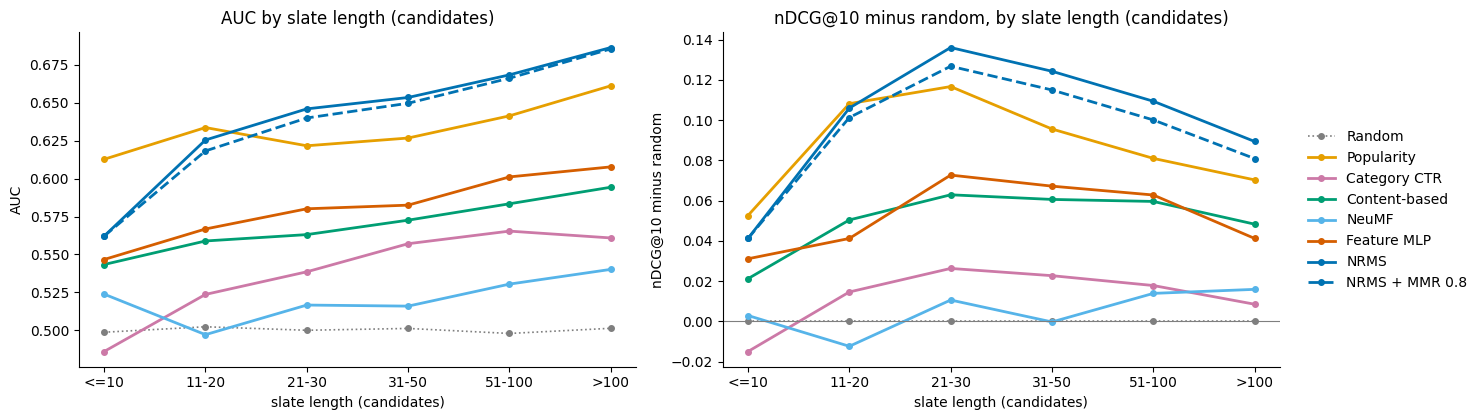

In [11]:
def bucket_table(col, labels):
    rows = []
    for m, per in PER.items():
        g = per.groupby(col, observed=False)[METRICS].mean()
        g["n_impressions"] = per.groupby(col, observed=False).size()
        g["model"] = m
        rows.append(g.reset_index())
    t = pd.concat(rows)
    t[col] = pd.Categorical(t[col], categories=labels, ordered=True)
    return t.round(4)


slate_t = save(bucket_table("slate_bucket", SLATE_LABELS).set_index(["model", "slate_bucket"]), "by_slate_length")
share = (imp.loc[PER["random (reference)"]["impression_id"], "slate_bucket"].value_counts(normalize=True).reindex(SLATE_LABELS) * 100).round(1)
print("Share of scored impressions per bucket (%):", share.to_dict())
display(slate_t["ndcg@10"].unstack("slate_bucket")[SLATE_LABELS].rename_axis(columns="nDCG@10"))
display(slate_t["auc"].unstack("slate_bucket")[SLATE_LABELS].rename_axis(columns="AUC"))

line_fig(slate_t, SLATE_LABELS, "slate length (candidates)", "fig_slate_length")

## 4. By user history length bucket
**What this does:** per-impression metrics averaged within buckets of how many articles the user had clicked before the impression (read from the history field).
**Why:** users with no history are a user cold-start problem, separate from the article cold-start. A model that relies on the user's history (content-based, NRMS-style) should do worse for them, and a popularity-style model should not. The README split shows the share of history-less sessions growing from 1.9% in Fit to 3.0% in Test, so this matters more at deployment time than the training data suggests.

Share of scored impressions per bucket (%): {'0': 3.0, '1-4': 11.0, '5-19': 37.0, '20-49': 28.5, '50+': 20.5}


nDCG@10,0,1-4,5-19,20-49,50+
model,,,,,
content_based,0.2872,0.3586,0.3451,0.3288,0.3189
ncf_nmf_neumf,0.2914,0.3379,0.3077,0.2751,0.2544
ncf_nmf_neumf_plus_id_masking_p0.1,0.2893,0.3366,0.3050,0.2711,0.2477
nrms_mmr_0.5,0.2979,0.3683,0.3610,0.3478,0.3358
nrms_mmr_0.6,0.3004,0.3747,0.3707,0.3607,0.3484
nrms_mmr_0.7,0.3038,0.3804,0.3791,0.3711,0.3591
nrms_mmr_0.8,0.3069,0.3847,0.3854,0.3783,0.3660
nrms_mmr_0.9,0.3082,0.3877,0.3893,0.3826,0.3704
nrms_mmr_1.0,0.3092,0.3890,0.3913,0.3849,0.3726


AUC,0,1-4,5-19,20-49,50+
model,,,,,
content_based,0.5000,0.5376,0.5593,0.5762,0.5825
ncf_nmf_neumf,0.5161,0.5233,0.5202,0.5166,0.5159
ncf_nmf_neumf_plus_id_masking_p0.1,0.5109,0.5198,0.5148,0.5082,0.5028
nrms_mmr_0.5,0.5329,0.5675,0.6006,0.6249,0.6304
nrms_mmr_0.6,0.5357,0.5730,0.6083,0.6343,0.6389
nrms_mmr_0.7,0.5397,0.5770,0.6142,0.6409,0.6450
nrms_mmr_0.8,0.5430,0.5801,0.6181,0.6447,0.6484
nrms_mmr_0.9,0.5438,0.5822,0.6205,0.6471,0.6503
nrms_mmr_1.0,0.5440,0.5834,0.6217,0.6483,0.6513


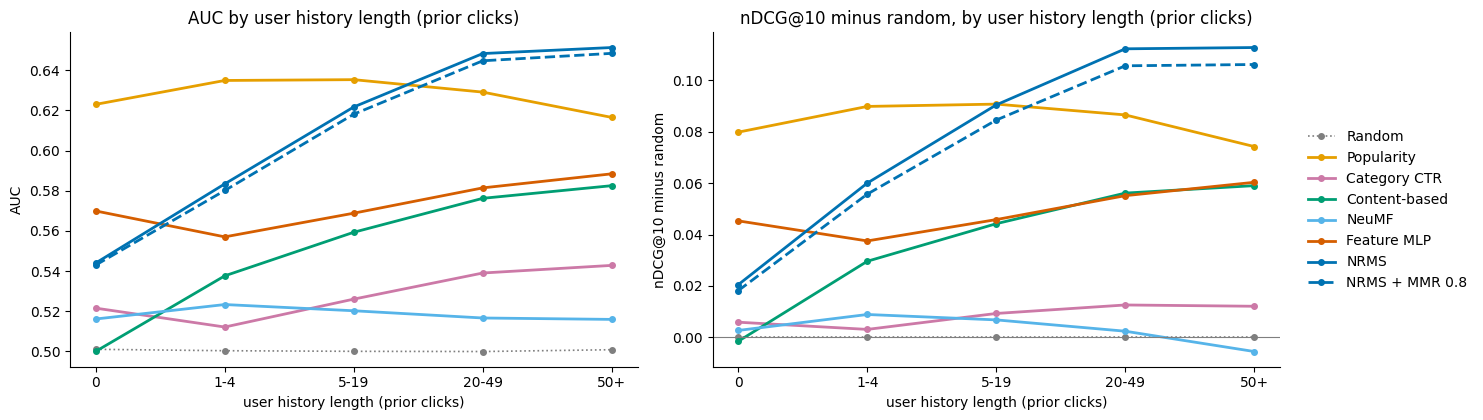

In [12]:
hist_t = save(bucket_table("hist_bucket", HIST_LABELS).set_index(["model", "hist_bucket"]), "by_history_length")
share = (imp.loc[PER["random (reference)"]["impression_id"], "hist_bucket"].value_counts(normalize=True).reindex(HIST_LABELS) * 100).round(1)
print("Share of scored impressions per bucket (%):", share.to_dict())
display(hist_t["ndcg@10"].unstack("hist_bucket")[HIST_LABELS].rename_axis(columns="nDCG@10"))
display(hist_t["auc"].unstack("hist_bucket")[HIST_LABELS].rename_axis(columns="AUC"))

line_fig(hist_t, HIST_LABELS, "user history length (prior clicks)", "fig_history_length")

## 5. Key quantitative insights for the abstract and slides
**What this does:** one row per model with the numbers the report needs: overall relevance, the cold/warm gap, how often cold clicks reach the top 10, and what the top-10 list looks like (categories, cold share, near-duplicates when `EMB` is set). It is saved as `results_step6.csv`. The cold exposure ratio is the cold share of the model's top-10 slots divided by the cold share of the candidates it chose from; below 1 the model shows cold articles less than their presence in the slate would suggest, above 1 more.
**Why:** this is the relevance-versus-exposure-versus-diversity trade-off the project is about, in one table. The sentences below are generated from the numbers, so check each one against the tables before it goes into the abstract.

model,random (reference),content_based,ncf_nmf_neumf,ncf_nmf_neumf_plus_id_masking_p0.1,nrms_mmr_0.5,nrms_mmr_0.6,nrms_mmr_0.7,nrms_mmr_0.8,nrms_mmr_0.9,nrms_mmr_1.0,step2_category_ctr,step2_popularity,step3_feature_mlp,step4_nrms_eval
n_impressions,376471.0000,376471.0000,376471.0000,376471.0000,376471.0000,376471.0000,376471.0000,376471.0000,376471.0000,376471.0000,376471.0000,376471.0000,376471.0000,376471.0000
auc,0.5002,0.5647,0.5185,0.5109,0.6080,0.6159,0.6218,0.6255,0.6277,0.6288,0.5315,0.6293,0.5751,0.6288
mrr,0.2193,0.2559,0.2212,0.2190,0.2752,0.2799,0.2841,0.2874,0.2896,0.2907,0.2183,0.2869,0.2562,0.2907
ndcg@5,0.2239,0.2692,0.2253,0.2223,0.2861,0.2946,0.3030,0.3094,0.3138,0.3162,0.2303,0.3137,0.2799,0.3162
ndcg@10,0.2872,0.3349,0.2903,0.2866,0.3510,0.3616,0.3706,0.3770,0.3809,0.3829,0.2972,0.3729,0.3377,0.3829
ndcg@10_cold,0.3815,0.4665,0.3646,0.3529,0.4223,0.4280,0.4333,0.4378,0.4409,0.4426,0.3451,0.3771,0.5169,0.4426
ndcg@10_mixed,0.1814,0.2462,0.1737,0.1623,0.2447,0.2608,0.2748,0.2846,0.2908,0.2938,0.1922,0.2465,0.2955,0.2938
ndcg@10_warm,0.2741,0.3085,0.2847,0.2844,0.3448,0.3561,0.3655,0.3719,0.3758,0.3777,0.2977,0.3892,0.2909,0.3777
ndcg@10_warm_minus_cold,-0.1074,-0.1580,-0.0799,-0.0685,-0.0775,-0.0719,-0.0678,-0.0659,-0.0651,-0.0649,-0.0474,0.0121,-0.2260,-0.0649
hit@10_cold_clicks,0.5139,0.6107,0.4995,0.4711,0.5548,0.5721,0.5863,0.5967,0.6043,0.6083,0.5296,0.4985,0.6988,0.6083


Saved: /content/drive/MyDrive/step6_outputs/results_step6.csv


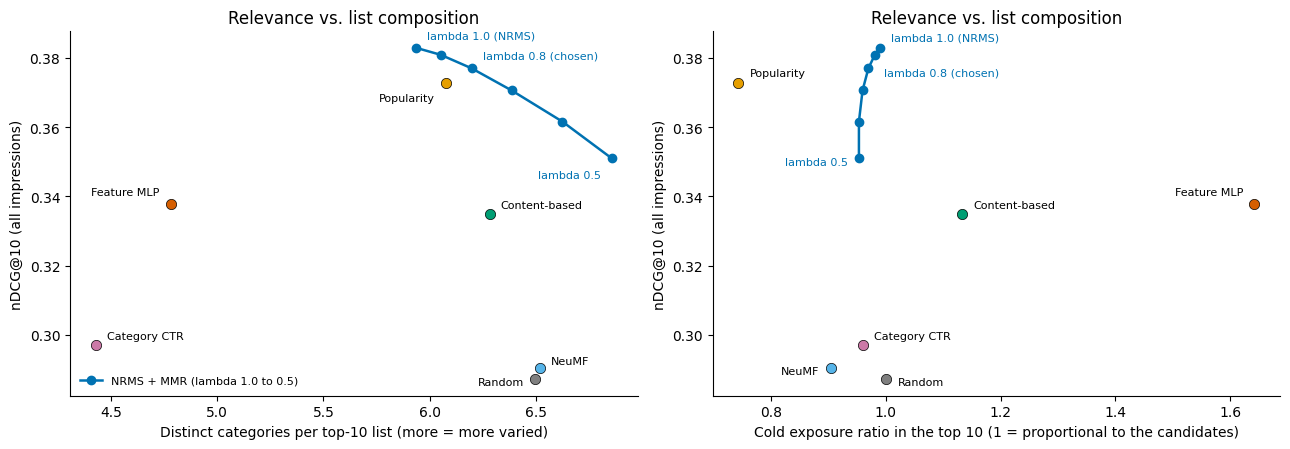

In [13]:
rows = {}
for m in PER:
    sg = SEGT[COLD_T].query("model == @m").set_index("segment")
    ck = CLKT[COLD_T].query("model == @m").set_index("clicked_article")
    r = {"n_impressions": int(sg.loc["all", "n_impressions"]), **sg.loc["all", METRICS].to_dict(),
         "ndcg@10_cold": sg.loc["cold", "ndcg@10"], "ndcg@10_mixed": sg.loc["mixed", "ndcg@10"], "ndcg@10_warm": sg.loc["warm", "ndcg@10"],
         "ndcg@10_warm_minus_cold": sg.loc["warm", "ndcg@10"] - sg.loc["cold", "ndcg@10"],
         "hit@10_cold_clicks": ck.loc["cold", "hit@10"], "hit@10_warm_clicks": ck.loc["warm", "hit@10"]}
    r.update(TOPSUM[m])
    rows[m] = r
S = pd.DataFrame(rows).T
S.index.name = "model"
S = S.round(4)
S.to_csv(RESULTS_CSV)
display(S.T)
print("Saved:", RESULTS_CSV)

# trade-off plot: relevance against what the list looks like (MMR as one line, other models as labelled points)
mmr = sorted([m for m in S.index if m.startswith("nrms_mmr_")], key=lambda m: -float(m.rsplit("_", 1)[-1]))
others = [m for m in fig_models(S.index) if not m.startswith("nrms_mmr") and m != "step4_nrms_eval"]
# label offsets (points) per panel so the labels do not sit on the line or on each other
OFFSET = [{"random (reference)": (-8, -4), "ncf_nmf_neumf": (8, 3), "step2_popularity": (-8, -13), "step2_category_ctr": (8, 4),
           "content_based": (8, 4), "step3_feature_mlp": (-8, 7)},
          {"random (reference)": (8, -4), "ncf_nmf_neumf": (-8, -4), "step2_popularity": (8, 5), "step2_category_ctr": (8, 4),
           "content_based": (8, 4), "step3_feature_mlp": (-8, 7)}]
MMR_LABEL = [{0: (8, 7), 1: (8, 7), 2: (-8, -14)}, {0: (8, 5), 1: (11, -5), 2: (-8, -5)}]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for k, (ax, (xcol, xlab)) in enumerate(zip(axes, [("top_unique_categories", f"Distinct categories per top-{TOP_K} list (more = more varied)"),
                                                   ("top_cold_exposure_ratio", f"Cold exposure ratio in the top {TOP_K} (1 = proportional to the candidates)")])):
    ax.plot(S.loc[mmr, xcol], S.loc[mmr, "ndcg@10"], color="#0072B2", lw=1.8, marker="o", ms=6, label="NRMS + MMR (lambda 1.0 to 0.5)")
    for i, (m, txt) in enumerate([(mmr[0], "lambda 1.0 (NRMS)"), ("nrms_mmr_0.8", "lambda 0.8 (chosen)"), (mmr[-1], "lambda 0.5")]):
        if m in S.index:
            dx, dy = MMR_LABEL[k][i]
            ax.annotate(txt, (S.loc[m, xcol], S.loc[m, "ndcg@10"]), fontsize=8, color="#0072B2", xytext=(dx, dy),
                        textcoords="offset points", ha="left" if dx > 0 else "right")
    for m in others:
        ax.scatter(S.loc[m, xcol], S.loc[m, "ndcg@10"], s=55, color=COLORS[m], edgecolor="black", linewidth=.5, zorder=3)
        dx, dy = OFFSET[k].get(m, (8, 4))
        ax.annotate(short(m), (S.loc[m, xcol], S.loc[m, "ndcg@10"]), fontsize=8, xytext=(dx, dy), textcoords="offset points", ha="left" if dx > 0 else "right")
    ax.set(xlabel=xlab, ylabel="nDCG@10 (all impressions)", title="Relevance vs. list composition")
axes[0].legend(loc="lower left", fontsize=8, frameon=False)
savefig("fig_tradeoff")

In [14]:
real = S.drop(index="random (reference)", errors="ignore")
if real.empty:
    print("Only the random reference has been scored so far - no insights yet. Rerun once score files exist.")
else:
    b = real["ndcg@10"].idxmax()
    r, rnd = real.loc[b], S.loc["random (reference)"]
    seg_share = SEG[COLD_T].value_counts(normalize=True)
    lines = [f"Best overall: {b} (nDCG@10 {r['ndcg@10']:.3f}, AUC {r['auc']:.3f}, MRR {r['mrr']:.3f}); the random reference gets nDCG@10 {rnd['ndcg@10']:.3f}.",
             f"Cold vs warm: {b} scores nDCG@10 {r['ndcg@10_cold']:.3f} on cold impressions and {r['ndcg@10_warm']:.3f} on warm ones (warm minus cold {r['ndcg@10_warm_minus_cold']:+.3f}). "
             f"Cold-only impressions are {100 * seg_share.get('cold', 0):.1f}% of Test, mixed {100 * seg_share.get('mixed', 0):.1f}%, warm {100 * seg_share.get('warm', 0):.1f}%.",
             f"Per click: {b} puts {100 * r['hit@10_cold_clicks']:.1f}% of cold-article clicks and {100 * r['hit@10_warm_clicks']:.1f}% of warm-article clicks in the top 10.",
             f"Smallest and largest cold gap across models: {real['ndcg@10_warm_minus_cold'].idxmin()} ({real['ndcg@10_warm_minus_cold'].min():+.3f}) and "
             f"{real['ndcg@10_warm_minus_cold'].idxmax()} ({real['ndcg@10_warm_minus_cold'].max():+.3f}); best cold-click hit@10: {real['hit@10_cold_clicks'].idxmax()} ({real['hit@10_cold_clicks'].max():.3f}).",
             f"Top-{TOP_K} list of {b}: {r['top_unique_categories']:.2f} distinct categories, cold share {100 * r['top_cold_share']:.1f}% of slots "
             f"(cold exposure ratio {r['top_cold_exposure_ratio']:.2f}; candidates are {100 * CAND_COLD_SHARE:.1f}% cold)."]
    sb = slate_t.loc[b]["ndcg@10"].reindex(SLATE_LABELS).dropna()
    hb = hist_t.loc[b]["ndcg@10"].reindex(HIST_LABELS).dropna()
    cb = cat_hit[b].dropna()
    lines += [f"Slate length ({b}): nDCG@10 is highest for {sb.idxmax()} candidates ({sb.max():.3f}) and lowest for {sb.idxmin()} ({sb.min():.3f}); compare with the random reference, which also depends on slate length.",
              f"History length ({b}): nDCG@10 {hb.iloc[0]:.3f} for bucket '{hb.index[0]}' vs {hb.iloc[-1]:.3f} for '{hb.index[-1]}'.",
              f"Category ({b}): hit@10 is best for {cb.idxmax()} ({cb.max():.2f}) and worst for {cb.idxmin()} ({cb.min():.2f}) among categories with enough clicks."]
    print("\n".join("- " + l for l in lines))

- Best overall: nrms_mmr_1.0 (nDCG@10 0.383, AUC 0.629, MRR 0.291); the random reference gets nDCG@10 0.287.
- Cold vs warm: nrms_mmr_1.0 scores nDCG@10 0.443 on cold impressions and 0.378 on warm ones (warm minus cold -0.065). Cold-only impressions are 20.5% of Test, mixed 9.7%, warm 69.8%.
- Per click: nrms_mmr_1.0 puts 60.8% of cold-article clicks and 54.9% of warm-article clicks in the top 10.
- Smallest and largest cold gap across models: step3_feature_mlp (-0.226) and step2_popularity (+0.012); best cold-click hit@10: step3_feature_mlp (0.699).
- Top-10 list of nrms_mmr_1.0: 5.94 distinct categories, cold share 20.3% of slots (cold exposure ratio 0.99; candidates are 20.6% cold).
- Slate length (nrms_mmr_1.0): nDCG@10 is highest for <=10 candidates (0.647) and lowest for >100 (0.135); compare with the random reference, which also depends on slate length.
- History length (nrms_mmr_1.0): nDCG@10 0.309 for bucket '0' vs 0.373 for '50+'.
- Category (nrms_mmr_1.0): hit@10 is best for

## **Summary of Test Results**

NRMS leads on every relevance metric except AUC, where Popularity is level with it. Test numbers are from step 6; the Tune column is from each owner's notebook.

| Model | Tune nDCG@10 | Test AUC | Test MRR | Test nDCG@5 | Test nDCG@10 |
| --- | --- | --- | --- | --- | --- |
| Random reference | – | 0.5002 | 0.2193 | 0.2239 | 0.2872 |
| Popularity (alpha 10) | 0.3311 | 0.6293 | 0.2869 | 0.3137 | 0.3729 |
| Category CTR (alpha 10) | 0.2695 | 0.5315 | 0.2183 | 0.2303 | 0.2972 |
| Content-based (TF-IDF/SVD) | – | 0.5647 | 0.2559 | 0.2692 | 0.3349 |
| NeuMF | 0.3357 | 0.5185 | 0.2212 | 0.2253 | 0.2903 |
| NeuMF + ID masking p=0.1 (ablation) | 0.3340 | 0.5109 | 0.2190 | 0.2223 | 0.2866 |
| Feature MLP | 0.3026 | 0.5751 | 0.2562 | 0.2799 | 0.3377 |
| NRMS | 0.3984 | 0.6288 | 0.2907 | 0.3162 | 0.3829 |
| NRMS + MMR (lambda 0.8) | 0.3941 | 0.6255 | 0.2874 | 0.3094 | 0.3770 |


**Training-set performance.** Only NRMS has a clean Fit-side number: AUC 0.7683 and nDCG@10 0.5069 on a 20,000-impression sample of its training impressions, against 0.6757 and 0.3984 on Tune and 0.6288 and 0.3829 on Test. NeuMF's Fit figure (nDCG@10 0.8918) comes from sampled 1:4 pools, so it is not comparable with the full-slate numbers. Popularity, Category CTR and content-based have no fitted parameters in this sense, so Tune plays the validation role.

Key findings, from step 6 on the Test day (15 Nov, 376,471 impressions).

1. **NRMS is the best relevance model; ID-only NCF is close to random.** NRMS reaches nDCG@10 0.3829 and AUC 0.6288, against 0.2872 and 0.5002 for a random ranking. NeuMF reaches only 0.2903 and 0.5185. Popularity matches NRMS on AUC (0.6293) but is lower on nDCG@10 (0.3729).
2. **Cold articles are clicked more than they are shown.** At the main threshold (fewer than 10 prior impressions), cold articles are 17.9% of displays but 23.5% of clicks.
3. **A popularity ranking hides cold articles.** Only 49.9% of cold-article clicks land in its top 10, below random (51.4%). Its top 10 holds 0.74 times the cold share of its candidates. NRMS gets 60.8% and 0.99.
4. **The feature MLP favours cold articles, but at a cost.** Its top 10 is 33.8% cold (ratio 1.64) and 69.9% of cold clicks reach it. Its warm-impression nDCG@10 is 0.2909, close to random (0.2741), and its overall nDCG@10 is 0.3377.
5. **MMR re-ranking buys category variety, not cold exposure.** At the Tune-selected lambda of 0.8, nDCG@10 falls from 0.3829 to 0.3770 (-1.5%) and distinct categories per top-10 list rise from 5.94 to 6.20. The cold share of the top 10 does not rise (0.2035 to 0.1994).
6. **The best model depends on user history.** Popularity beats NRMS for users with 0 to 4 prior clicks (0.4188 vs 0.3890 nDCG@10 at 1 to 4). NRMS wins clearly from 20 clicks upward (0.3849 vs 0.3592 at 20 to 49).